In [2]:
import pandas as pd
import os

In [3]:
pd.set_option('display.max_colwidth',200)

### Loading the data

In [4]:


base_path = "./data/LA"
eval_protocol_path = os.path.join(base_path, "ASVspoof2019_LA_cm_protocols", "ASVspoof2019.LA.cm.eval.trl.txt")
eval_audio_folder = os.path.join(base_path, "ASVspoof2019_LA_eval", "flac")

# collumns based on the README of the original dataset
columns = ["speaker_id", "audio_file_name", "ignored", "system_id", "label"]

df_eval = pd.read_csv(eval_protocol_path, sep=" ", header=None, names=columns)

df_eval = df_eval.drop(columns=["ignored"])


df_eval['file_path'] = df_eval['audio_file_name'].apply(lambda x: os.path.join(eval_audio_folder, x + ".flac"))

df_eval.sample(10)

,speaker_id,audio_file_name,system_id,label,file_path
32335,LA_0035,LA_E_3411878,A15,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_3411878.flac
41262,LA_0008,LA_E_6016987,A12,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6016987.flac
67588,LA_0023,LA_E_7055566,A17,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_7055566.flac
71200,LA_0026,LA_E_1113447,A18,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_1113447.flac
41638,LA_0025,LA_E_5474791,A19,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5474791.flac
34046,LA_0020,LA_E_4000699,A15,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_4000699.flac
69770,LA_0007,LA_E_8970720,A14,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_8970720.flac
23529,LA_0042,LA_E_4317152,A16,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_4317152.flac
26785,LA_0029,LA_E_8593050,A09,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_8593050.flac
32625,LA_0030,LA_E_7418022,A16,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_7418022.flac


In [5]:
df_eval

,speaker_id,audio_file_name,system_id,label,file_path
0,LA_0039,LA_E_2834763,A11,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2834763.flac
1,LA_0014,LA_E_8877452,A14,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_8877452.flac
2,LA_0040,LA_E_6828287,A16,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6828287.flac
3,LA_0022,LA_E_6977360,A09,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6977360.flac
4,LA_0031,LA_E_5932896,A13,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5932896.flac
...,...,...,...,...,...
71232,LA_0004,LA_E_1665632,-,bonafide,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_1665632.flac
71233,LA_0038,LA_E_5085671,A09,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5085671.flac
71234,LA_0012,LA_E_4926022,A16,spoof,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_4926022.flac
71235,LA_0052,LA_E_2894498,-,bonafide,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2894498.flac


### Data cleaning

In [6]:

df_eval['label'] = df_eval['label'].map({'bonafide': 0, 'spoof': 1})

df_eval = df_eval.drop(columns=['audio_file_name'])

#sanity check
df_eval['file_exists'] = df_eval['file_path'].apply(os.path.exists)
print(f"Missing files: {len(df_eval[df_eval['file_exists'] == False])}")
df_eval

Missing files: 0


,speaker_id,system_id,label,file_path,file_exists
0,LA_0039,A11,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2834763.flac,True
1,LA_0014,A14,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_8877452.flac,True
2,LA_0040,A16,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6828287.flac,True
3,LA_0022,A09,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6977360.flac,True
4,LA_0031,A13,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5932896.flac,True
...,...,...,...,...,...
71232,LA_0004,-,0,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_1665632.flac,True
71233,LA_0038,A09,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5085671.flac,True
71234,LA_0012,A16,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_4926022.flac,True
71235,LA_0052,-,0,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2894498.flac,True


In [7]:
df_eval = df_eval.drop(columns=['file_exists'])

In [8]:
df_eval

,speaker_id,system_id,label,file_path
0,LA_0039,A11,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2834763.flac
1,LA_0014,A14,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_8877452.flac
2,LA_0040,A16,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6828287.flac
3,LA_0022,A09,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6977360.flac
4,LA_0031,A13,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5932896.flac
...,...,...,...,...
71232,LA_0004,-,0,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_1665632.flac
71233,LA_0038,A09,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5085671.flac
71234,LA_0012,A16,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_4926022.flac
71235,LA_0052,-,0,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2894498.flac


In [9]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

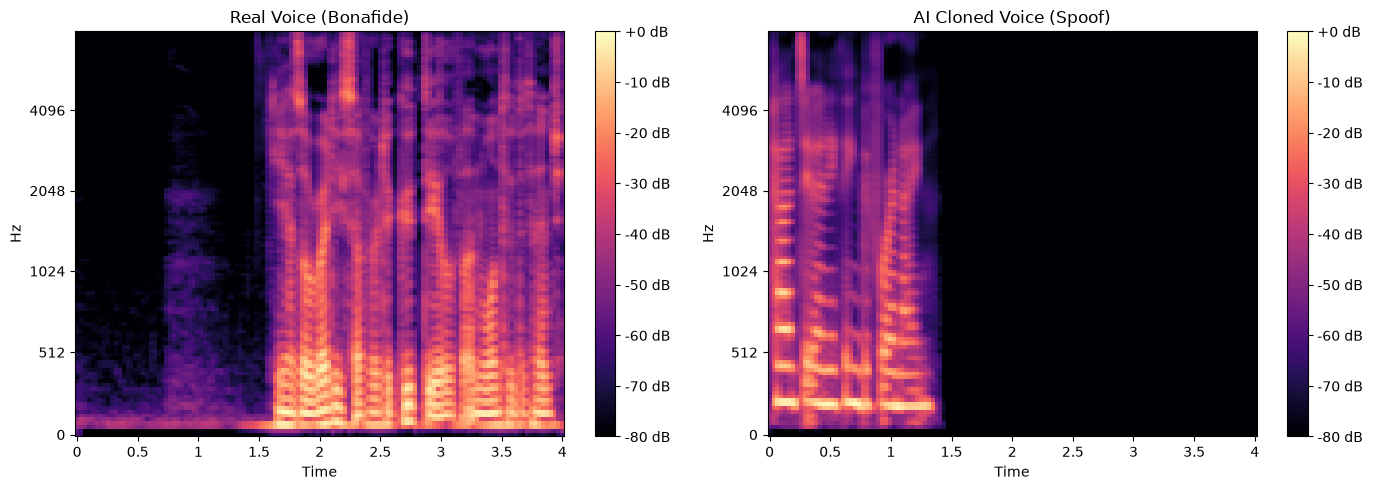

In [10]:
def generate_mel_spectrogram(file_path, target_seconds=4, sample_rate=16000):
    
    target_length = target_seconds * sample_rate
    
    
    y, sr = librosa.load(file_path, sr=sample_rate)
    
    
    y_fixed = librosa.util.fix_length(data=y, size=target_length)
    
    
    mel_spec = librosa.feature.melspectrogram(y=y_fixed, sr=sr, n_mels=128)
    
    
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    
    return mel_spec_db


sample_real_path = df_eval[df_eval['label'] == 0].iloc[0]['file_path']
sample_fake_path = df_eval[df_eval['label'] == 1].iloc[0]['file_path']


spec_real = generate_mel_spectrogram(sample_real_path)
spec_fake = generate_mel_spectrogram(sample_fake_path)


fig, ax = plt.subplots(1, 2, figsize=(14, 5))

img1 = librosa.display.specshow(spec_real, sr=16000, x_axis='time', y_axis='mel', ax=ax[0])
ax[0].set_title('Real Voice (Bonafide)')
fig.colorbar(img1, ax=ax[0], format='%+2.0f dB')

img2 = librosa.display.specshow(spec_fake, sr=16000, x_axis='time', y_axis='mel', ax=ax[1])
ax[1].set_title('AI Cloned Voice (Spoof)')
fig.colorbar(img2, ax=ax[1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

In [11]:
from tqdm import tqdm

In [12]:
df_eval_img = df_eval.copy()
df_eval_img

,speaker_id,system_id,label,file_path
0,LA_0039,A11,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2834763.flac
1,LA_0014,A14,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_8877452.flac
2,LA_0040,A16,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6828287.flac
3,LA_0022,A09,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6977360.flac
4,LA_0031,A13,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5932896.flac
...,...,...,...,...
71232,LA_0004,-,0,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_1665632.flac
71233,LA_0038,A09,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5085671.flac
71234,LA_0012,A16,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_4926022.flac
71235,LA_0052,-,0,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2894498.flac


In [13]:

output_base_dir = "./data/dataset_img/eval"

def compute_img_path(row):
    subfolder = "bonafide" if row['label'] == 0 else "spoofed"
    return os.path.join(output_base_dir, subfolder, f"sample_{row.name}.png")


df_eval_img['img_path'] = df_eval_img.apply(compute_img_path, axis=1)

os.makedirs(os.path.join(output_base_dir, "bonafide"), exist_ok=True)
os.makedirs(os.path.join(output_base_dir, "spoofed"), exist_ok=True)

print("Starting Mel-spectrogram export to disk...")


for idx, row in tqdm(df_eval.iterrows(), total=len(df_eval)):
    file_path = row['file_path']
    label = row['label']
    
    try:
        
        spec_db = generate_mel_spectrogram(file_path)
        
        
        if label == 0:
            dest_folder = os.path.join(output_base_dir, "bonafide")
        else:
            dest_folder = os.path.join(output_base_dir, "spoofed")
            
        
        img_filename = f"sample_{idx}.png"
        img_path = os.path.join(dest_folder, img_filename)
        
        
        plt.imsave(img_path, spec_db, cmap='magma', origin='lower')
        
    except Exception as e:
        print(f"Error processing index {idx} ({file_path}): {e}")
        continue

print(f"Export complete! Check your directory: {output_base_dir}")

Starting Mel-spectrogram export to disk...


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 71237/71237 [11:13<00:00, 105.79it/s]

Export complete! Check your directory: ./data/dataset_img/eval


In [14]:
df_eval_img

,speaker_id,system_id,label,file_path,img_path
0,LA_0039,A11,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2834763.flac,./data/dataset_img/eval/spoofed/sample_0.png
1,LA_0014,A14,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_8877452.flac,./data/dataset_img/eval/spoofed/sample_1.png
2,LA_0040,A16,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6828287.flac,./data/dataset_img/eval/spoofed/sample_2.png
3,LA_0022,A09,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_6977360.flac,./data/dataset_img/eval/spoofed/sample_3.png
4,LA_0031,A13,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5932896.flac,./data/dataset_img/eval/spoofed/sample_4.png
...,...,...,...,...,...
71232,LA_0004,-,0,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_1665632.flac,./data/dataset_img/eval/bonafide/sample_71232.png
71233,LA_0038,A09,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_5085671.flac,./data/dataset_img/eval/spoofed/sample_71233.png
71234,LA_0012,A16,1,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_4926022.flac,./data/dataset_img/eval/spoofed/sample_71234.png
71235,LA_0052,-,0,./data/LA/ASVspoof2019_LA_eval/flac/LA_E_2894498.flac,./data/dataset_img/eval/bonafide/sample_71235.png


In [15]:
df_export = df_eval_img.drop(columns = ['file_path'])
df_export

,speaker_id,system_id,label,img_path
0,LA_0039,A11,1,./data/dataset_img/eval/spoofed/sample_0.png
1,LA_0014,A14,1,./data/dataset_img/eval/spoofed/sample_1.png
2,LA_0040,A16,1,./data/dataset_img/eval/spoofed/sample_2.png
3,LA_0022,A09,1,./data/dataset_img/eval/spoofed/sample_3.png
4,LA_0031,A13,1,./data/dataset_img/eval/spoofed/sample_4.png
...,...,...,...,...
71232,LA_0004,-,0,./data/dataset_img/eval/bonafide/sample_71232.png
71233,LA_0038,A09,1,./data/dataset_img/eval/spoofed/sample_71233.png
71234,LA_0012,A16,1,./data/dataset_img/eval/spoofed/sample_71234.png
71235,LA_0052,-,0,./data/dataset_img/eval/bonafide/sample_71235.png


In [16]:
df_export.to_csv("./data/dataset_img/eval/metadata_eval.csv", index = False)